# Midterm Project – Deep Learning
## Part 1: DNN (ANN) Model – Customer Churn Prediction

---
### 1. Problem Definition
Telecom companies lose a large share of revenue when customers cancel their subscription (*churn*). Winning a new customer costs far more than keeping an existing one, so companies want to identify customers who are **likely to churn before they leave** and target them with retention offers.

**Task:** binary classification. Given a customer's account information (contract type, tenure, services, charges, ...), predict whether the customer will churn (`Yes` / `No`).

### 2. Dataset Description and Source
- **Name:** Telco Customer Churn (IBM sample dataset)
- **Source link:** https://github.com/IBM/telco-customer-churn-on-icp4d (also on Kaggle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
- **Size:** 7,043 customers, 21 columns (19 input features + `customerID` + target `Churn`)
- **Features:** demographics (gender, senior citizen, partner, dependents), account info (tenure, contract, paperless billing, payment method), services (phone, internet, security, backup, streaming, ...), charges (monthly, total).
- **Target:** `Churn` (about 26.5% of customers churn, so the classes are imbalanced).

### 3. Proposed Solution
A fully connected **Deep Neural Network** (ANN) that takes the preprocessed customer features and outputs the probability of churn.
- Categorical features are one-hot encoded and numeric features are standardised.
- Class imbalance is handled with a weighted loss (`pos_weight`).
- Overfitting is controlled with Batch Normalisation, Dropout, weight decay and early stopping.
- The decision threshold is tuned on the validation set (F1) instead of using the default 0.5.

In [1]:
import random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay, precision_recall_curve)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)

Device: cpu | torch 2.11.0+cpu


### 4. Load the Data

In [2]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
try:
    df = pd.read_csv(URL)
except Exception as e:
    print("Could not download automatically:", e)
    print("Download the CSV from the Kaggle link above and upload it now.")
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(next(iter(up)))

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


object     18
int64       2
float64     1
Name: count, dtype: int64 

Missing values per column (raw):
 Series([], dtype: int64) 

Target distribution:
 Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


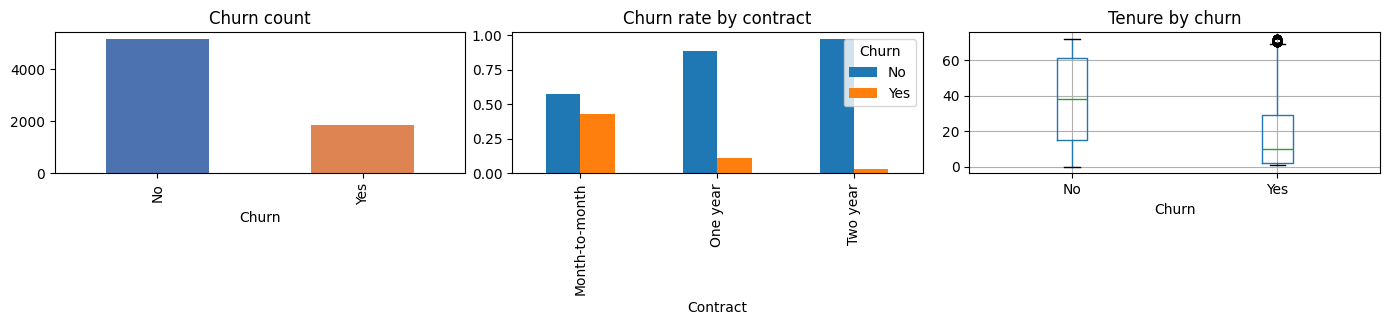

In [3]:
print(df.dtypes.value_counts(), "\n")
print("Missing values per column (raw):\n", df.isna().sum()[df.isna().sum() > 0], "\n")
print("Target distribution:\n", df["Churn"].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
df["Churn"].value_counts().plot(kind="bar", ax=ax[0], color=["#4c72b0", "#dd8452"], title="Churn count")
pd.crosstab(df["Contract"], df["Churn"], normalize="index").plot(kind="bar", ax=ax[1], title="Churn rate by contract")
df.boxplot(column="tenure", by="Churn", ax=ax[2]); ax[2].set_title("Tenure by churn"); plt.suptitle("")
plt.tight_layout(); plt.show()

### 5. Data Preprocessing
1. `TotalCharges` is stored as text with blank strings for brand-new customers (tenure = 0) -> convert to numeric and fill those with 0.
2. Drop `customerID` (identifier, no predictive value).
3. Encode the target: `Yes` -> 1, `No` -> 0.
4. Stratified split: **70% train / 15% validation / 15% test**.
5. `StandardScaler` for numeric columns and `OneHotEncoder` for categorical columns. The transformer is **fit on the training set only** to avoid data leakage, and it is saved with the model so inference uses identical preprocessing.
6. Class imbalance -> `pos_weight = n_negative / n_positive` in the loss.

In [4]:
data = df.copy()
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce").fillna(0.0)
y = (data["Churn"] == "Yes").astype(int).values
X = data.drop(columns=["customerID", "Churn"])

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

X_train_raw, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
X_val = preprocessor.transform(X_val_raw).astype(np.float32)
X_test = preprocessor.transform(X_test_raw).astype(np.float32)

print("Train/Val/Test:", X_train.shape, X_val.shape, X_test.shape)
print("Churn rate  train/val/test:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

def to_loader(Xa, ya, bs, shuffle):
    ds = torch.utils.data.TensorDataset(torch.tensor(Xa), torch.tensor(ya, dtype=torch.float32))
    return torch.utils.data.DataLoader(ds, batch_size=bs, shuffle=shuffle)

train_loader = to_loader(X_train, y_train, 128, True)
val_loader = to_loader(X_val, y_val, 512, False)
test_loader = to_loader(X_test, y_test, 512, False)

Train/Val/Test: (4930, 46) (1056, 46) (1057, 46)
Churn rate  train/val/test: 0.265 0.265 0.266


### 6. Model Architecture
Fully connected network: `Input -> [Linear -> BatchNorm -> ReLU -> Dropout] x 3 -> Linear(1)`

| Layer | Units | Notes |
|---|---|---|
| Dense 1 | 128 | BatchNorm, ReLU, Dropout 0.3 |
| Dense 2 | 64 | BatchNorm, ReLU, Dropout 0.3 |
| Dense 3 | 32 | BatchNorm, ReLU, Dropout 0.3 |
| Output | 1 | raw logit; sigmoid gives the churn probability |

- **Loss:** `BCEWithLogitsLoss` with `pos_weight` (binary classification + class imbalance)
- **Optimizer:** Adam (lr 1e-3, weight decay 1e-4), `ReduceLROnPlateau` scheduler
- **Regularisation:** Dropout, BatchNorm, weight decay, early stopping (patience 12)

In [5]:
class ChurnDNN(nn.Module):
    def __init__(self, in_dim, hidden=(128, 64, 32), dropout=0.3):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)

config = {"in_dim": X_train.shape[1], "hidden": (128, 64, 32), "dropout": 0.3}
model = ChurnDNN(**config).to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

ChurnDNN(
  (net): Sequential(
    (0): Linear(in_features=46, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 16833


### 7. Training

In [6]:
pos_weight = torch.tensor((y_train == 0).sum() / (y_train == 1).sum(), dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += ((logits > 0).float() == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

EPOCHS, PATIENCE = 150, 12
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val, best_state, wait = float("inf"), None, 0

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, True)
    va_loss, va_acc = run_epoch(val_loader, False)
    scheduler.step(va_loss)
    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
        history[k].append(v)
    if va_loss < best_val - 1e-4:
        best_val, wait = va_loss, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | val loss {va_loss:.4f} acc {va_acc:.3f}")
    if wait >= PATIENCE:
        print(f"Early stopping at epoch {epoch} (best val loss {best_val:.4f})")
        break

model.load_state_dict(best_state)

Epoch   1 | train loss 0.8386 acc 0.685 | val loss 0.7780 acc 0.679
Epoch   5 | train loss 0.7215 acc 0.735 | val loss 0.7290 acc 0.710
Epoch  10 | train loss 0.7128 acc 0.747 | val loss 0.7320 acc 0.706
Epoch  15 | train loss 0.6941 acc 0.750 | val loss 0.7289 acc 0.723
Early stopping at epoch 18 (best val loss 0.7222)


<All keys matched successfully>

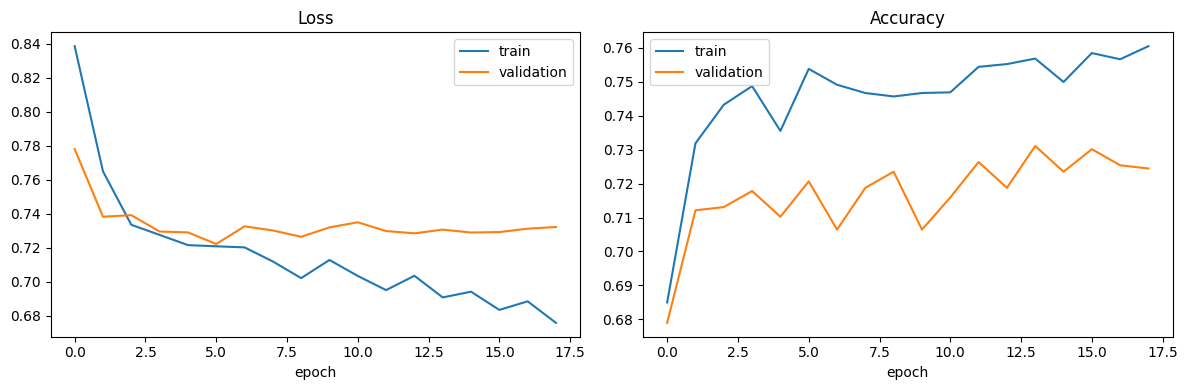

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

### 8. Evaluation
Accuracy alone is misleading with 26.5% churners (always predicting "No" already gives ~73.5%), so we also report precision, recall, F1 and ROC-AUC. The threshold is chosen on the **validation** set to maximise F1, then applied unchanged to the **test** set.

Threshold chosen on validation set: 0.633

TEST SET RESULTS
  Accuracy  : 0.7881
  Precision : 0.5893
  Recall    : 0.6690
  F1        : 0.6267
  ROC-AUC   : 0.8434

               precision    recall  f1-score   support

    No churn       0.87      0.83      0.85       776
       Churn       0.59      0.67      0.63       281

    accuracy                           0.79      1057
   macro avg       0.73      0.75      0.74      1057
weighted avg       0.80      0.79      0.79      1057



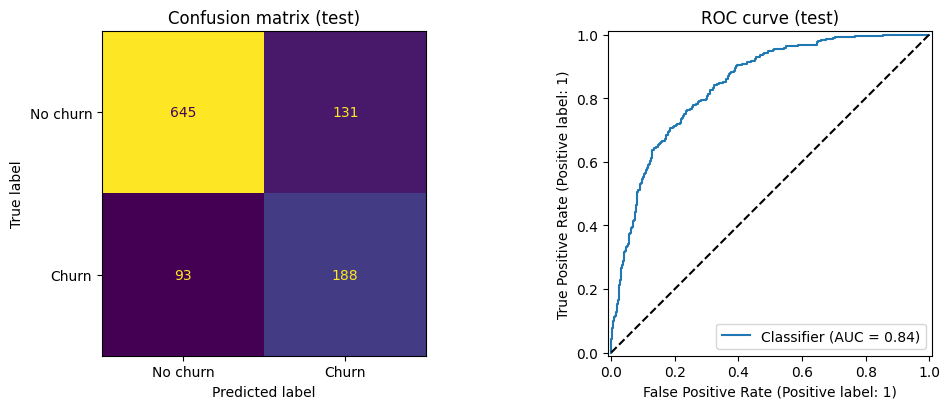

In [8]:
@torch.no_grad()
def predict_proba(loader):
    model.eval()
    out = []
    for xb, _ in loader:
        out.append(torch.sigmoid(model(xb.to(device))).cpu().numpy())
    return np.concatenate(out)

val_probs = predict_proba(val_loader)
test_probs = predict_proba(test_loader)

prec, rec, thr = precision_recall_curve(y_val, val_probs)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
best_threshold = float(thr[np.argmax(f1s)])
print(f"Threshold chosen on validation set: {best_threshold:.3f}")

test_pred = (test_probs >= best_threshold).astype(int)
results = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred),
    "Recall": recall_score(y_test, test_pred),
    "F1": f1_score(y_test, test_pred),
    "ROC-AUC": roc_auc_score(y_test, test_probs),
}
print("\nTEST SET RESULTS")
for k, v in results.items():
    print(f"  {k:10s}: {v:.4f}")
print("\n", classification_report(y_test, test_pred, target_names=["No churn", "Churn"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=["No churn", "Churn"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (test)")
RocCurveDisplay.from_predictions(y_test, test_probs, ax=ax[1]); ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC curve (test)")
plt.tight_layout(); plt.show()

### 9. Save the Trained Model (`.joblib`)
The file stores everything needed for inference in one object: the network weights, the architecture settings, the fitted preprocessing transformer, the tuned threshold and the expected input columns.

In [9]:
artifact = {
    "model_class": "ChurnDNN",
    "config": config,
    "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
    "preprocessor": preprocessor,
    "threshold": best_threshold,
    "feature_columns": list(X.columns),
    "test_metrics": results,
}
joblib.dump(artifact, "churn_dnn_model.joblib")

import os
print("Saved churn_dnn_model.joblib  (%.1f KB)" % (os.path.getsize("churn_dnn_model.joblib") / 1024))

Saved churn_dnn_model.joblib  (81.7 KB)


### 10. Inference
Load the `.joblib` file from disk (as a deployment script would), rebuild the network, and predict churn for new customers. The class `ChurnDNN` defined above must exist in the session (in a fresh session, re-run the model-class cell first).

In [10]:
# --- load the saved model exactly as a separate application would ---
art = joblib.load("churn_dnn_model.joblib")
infer_model = ChurnDNN(**art["config"])
infer_model.load_state_dict(art["state_dict"])
infer_model.eval()

def predict_churn(records):
    """records: a dict (one customer), a list of dicts, or a DataFrame with the original Telco columns."""
    if isinstance(records, dict):
        records = [records]
    frame = pd.DataFrame(records)[art["feature_columns"]]
    frame["TotalCharges"] = pd.to_numeric(frame["TotalCharges"], errors="coerce").fillna(0.0)
    x = torch.tensor(art["preprocessor"].transform(frame).astype(np.float32))
    with torch.no_grad():
        probs = torch.sigmoid(infer_model(x)).numpy()
    return pd.DataFrame({
        "churn_probability": probs.round(4),
        "prediction": np.where(probs >= art["threshold"], "Churn", "No churn"),
    })

# 1) a hand-written new customer: month-to-month, fibre, no add-ons, short tenure (high-risk profile)
new_customer = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 2,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "Yes", "StreamingMovies": "Yes", "Contract": "Month-to-month",
    "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 95.7, "TotalCharges": 191.4,
}
print("Hand-written customer:")
display(predict_churn(new_customer))

# 2) a loyal-customer profile: two-year contract, long tenure
loyal = dict(new_customer, tenure=60, Contract="Two year", PaymentMethod="Credit card (automatic)",
             OnlineSecurity="Yes", TechSupport="Yes", MonthlyCharges=70.0, TotalCharges=4200.0)
print("Loyal customer:")
display(predict_churn(loyal))

# 3) five real held-out test customers with their true labels
sample = X_test_raw.head(5)
out = predict_churn(sample)
out["actual"] = np.where(y_test[:5] == 1, "Churn", "No churn")
print("Held-out test customers:")
display(out)

# 4) sanity check: reloaded model reproduces the in-memory test probabilities
reloaded_probs = predict_churn(X_test_raw)["churn_probability"].values
print("Max difference vs. in-memory model:", float(np.abs(reloaded_probs - test_probs).max()))

Hand-written customer:


,churn_probability,prediction
0,0.8978,Churn


Loyal customer:


,churn_probability,prediction
0,0.1779,No churn


Held-out test customers:


,churn_probability,prediction,actual
0,0.6760,Churn,Churn
1,0.2518,No churn,No churn
2,0.0937,No churn,No churn
3,0.3572,No churn,No churn
4,0.0379,No churn,No churn


Max difference vs. in-memory model: 4.9948692321777344e-05
